# NN_L9_pr_curves

**Lecture 9 of Neural Networks and Deep Learning (NN), Elliptic Bitcoin transaction graph (Weber et al., 2019). Precision-recall curves on the test steps for logistic regression, random forest, GCN and random forest + GCN (scores averaged over seeds).**

Neural Networks and Deep Learning (NN), Lecture 9 · Daniel Traian Pele, Bucharest University of Economic Studies

[Open in Colab](https://colab.research.google.com/github/danpele/NEURAL_BIZ/blob/main/Quantlets/L9/NN_L9_pr_curves/NN_L9_pr_curves.ipynb)

In [1]:
import os
# course data: the local copy of the repository if there is one, else the public repository on GitHub
_LOCAL = os.path.join('..', '..', '..', 'data', 'clean')
DATA = _LOCAL + os.sep if os.path.isdir(_LOCAL) else 'https://raw.githubusercontent.com/danpele/NEURAL_BIZ/main/data/clean/'
REPO = os.path.join('..', '..', '..') + os.sep if os.path.isdir(_LOCAL) else 'https://raw.githubusercontent.com/danpele/NEURAL_BIZ/main/'

In [2]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
warnings.filterwarnings('ignore')
# course chart style: transparent background, no gridlines, legend at the bottom outside the axes, four-digit years
plt.rcParams.update({
    'figure.facecolor': 'none', 'axes.facecolor': 'none', 'savefig.transparent': True,
    'axes.grid': False, 'axes.spines.top': False, 'axes.spines.right': False,
    'axes.edgecolor': '#222222', 'axes.labelcolor': '#222222', 'xtick.color': '#222222', 'ytick.color': '#222222',
    'text.color': '#222222', 'font.size': 11, 'axes.labelsize': 11, 'legend.fontsize': 10.5, 'legend.frameon': False,
    'lines.linewidth': 1.4, 'font.family': 'DejaVu Sans'})
SERIES = ['#2a78d6', '#eb6834', '#1baf7a', '#eda100', '#e87ba4', '#008300', '#6250d6', '#e34948']
PAL = {'data': '#2a78d6', 'model': '#eb6834', 'benchmark': '#1baf7a', 'alt': '#eda100',
       'train': '#2a78d6', 'valid': '#eb6834', 'test': '#6250d6', 'positive': '#e34948', 'negative': '#2a78d6'}


def legend_bottom(fig, ncol=4):
    h, l_ = [], []
    for ax in fig.axes:
        for hh, ll in zip(*ax.get_legend_handles_labels()):
            if ll not in l_:
                h.append(hh); l_.append(ll)
    if h:
        fig.legend(h, l_, loc='lower center', ncol=min(ncol, len(h)), bbox_to_anchor=(0.5, 0.0), frameon=False)


def show(key, label, value):
    # print a number of the slide; [key] = its name in lectures/Lk/Lk_numbers.json
    print(f'{label} = {value}   [{key}]')

Base rate = share of illicit among the labelled test transactions.

illicit among labelled test transactions (%) = 6.5   [data.pct_test_illicit]
PR-AUC, logistic regression = 0.311   [models.lr_all.ap]


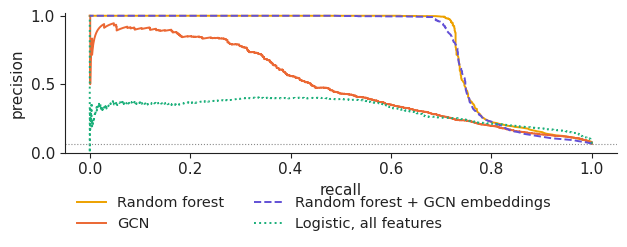

In [3]:
LAB = {'lr_all': 'Logistic, all features', 'rf': 'Random forest', 'gcn': 'GCN', 'rf_emb': 'Random forest + GCN embeddings'}
COL = {'lr_all': PAL['benchmark'], 'rf': PAL['alt'], 'gcn': PAL['model'], 'rf_emb': '#6250d6'}
LS = {'lr_all': ':', 'rf': '-', 'gcn': '-', 'rf_emb': '--'}
from sklearn.metrics import precision_recall_curve, average_precision_score
s = pd.read_csv(REPO + 'lectures/L9/results/' + 'test_scores.csv')
show('data.pct_test_illicit', 'illicit among labelled test transactions (%)', round(100 * float(s.y.mean()), 2))
show('models.lr_all.ap', 'PR-AUC, logistic regression', round(float(average_precision_score(s.y, s.lr_all)), 3))
fig, ax = plt.subplots(figsize=(6.4, 2.5))
for k in ['rf', 'gcn', 'rf_emb', 'lr_all']:
    p, r, _ = precision_recall_curve(s.y, s[k])
    ax.plot(r, p, LS[k], color=COL[k], label=LAB[k])
ax.axhline(s.y.mean(), color='#8a8a8a', lw=0.8, ls=':')
ax.set_ylim(0, 1.02); ax.set_xlabel('recall'); ax.set_ylabel('precision')
legend_bottom(fig, ncol=2)
fig.tight_layout(rect=(0, 0.12, 1, 1))
fig.savefig('pr_curves.png', dpi=200, transparent=True, bbox_inches='tight')
plt.show()